# DATA 266 - Lab 2 - Part 2: Fine-tuning Stable Diffusion 1.5 with LoRA
## Notebook 3 of 3: Generation, evaluation and safety (tasks 2.3 and 2.4)

This notebook uses the two LoRA runs from notebook 2 and the 20 fixed prompts from notebook 1.

1. Generate 2 images per prompt (seeds 0 and 1) with the base model and with both runs, using the same sampler settings: 40 images per model.
2. Show side-by-side grids for 8 prompts.
3. Measure: **KID** and **CLIP score** (primary), **LPIPS diversity** (secondary), **GPU-hours and peak memory** (efficiency), and prepare the **blinded human evaluation**.
4. Pick the final run, show failure modes, and run the safety checks (NSFW filter and memorization check).
5. Upload the models and all generated images to Hugging Face.

Everything reported here is computed in this notebook.

In [1]:
# Cell 1 - Reproducibility and environment information

import os
import sys
import random
import subprocess
from importlib.metadata import version, PackageNotFoundError

import numpy as np
import torch

SEED = 266

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


def library_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return "not installed"


# Git commit. Git is not always on the PATH inside a notebook kernel, so a few usual places are tried
commit = ""
git = "git"
for git in ["git", r"C:\Program Files\Git\cmd\git.exe", os.path.expanduser(r"~\AppData\Local\Programs\Git\cmd\git.exe")]:
    try:
        result = subprocess.run([git, "rev-parse", "--short", "HEAD"], capture_output=True, text=True)
        commit = result.stdout.strip()
        break
    except FileNotFoundError:
        continue

run_info = {
    "commit": commit or "no Git repository here",
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "diffusers": library_version("diffusers"),
    "transformers": library_version("transformers"),
    "torchmetrics": library_version("torchmetrics"),
    "lpips": library_version("lpips"),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    "seed": SEED
}

print(run_info)

{'commit': '9cf9213', 'python': '3.11.18', 'torch': '2.14.1+cu130', 'diffusers': '0.42.1', 'transformers': '5.22.2', 'torchmetrics': '1.9.0', 'lpips': '0.1.4', 'gpu': 'NVIDIA GeForce RTX 4090', 'seed': 266}


## 1. Settings and paths

In [2]:
import json
import io
import time
import base64
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

BASE_MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"

# Same sampler settings for every model
SEEDS = [0, 1]
STEPS = 30
GUIDANCE = 7.5
SIZE = 512

# Hugging Face
HF_USER = "SawantTej"
UPLOAD_TO_HF = True

DATA_DIR = Path("../data/part2")
OUT_DIR = Path("../outputs/part2")
RUN_DIR = OUT_DIR / "runs"
GEN_DIR = OUT_DIR / "generated"
GRID_DIR = OUT_DIR / "grids"
METRIC_DIR = OUT_DIR / "metrics"
HUMAN_DIR = OUT_DIR / "human_eval"
SAFETY_DIR = OUT_DIR / "safety"
TRAIN_DIR = OUT_DIR / "data_prep" / "images" / "train"
TEST_DIR = OUT_DIR / "data_prep" / "images" / "test"

for folder in [GEN_DIR, GRID_DIR, METRIC_DIR, HUMAN_DIR / "pairs", HUMAN_DIR / "ratings", SAFETY_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

RUN_NAMES = ["run1_lora_r8", "run2_lora_r32"]
MODELS = ["base"] + RUN_NAMES

prompts = json.loads((DATA_DIR / "prompts.json").read_text(encoding="utf-8"))
training_table = pd.read_csv(METRIC_DIR / "training_table.csv").set_index("run")

print("Prompts:", len(prompts), "| models:", MODELS, "| seeds:", SEEDS)
print(training_table[["rank", "trainable_parameters", "steps", "batch_size", "peak_gpu_memory_gb", "training_minutes"]].to_string())

Prompts: 20 | models: ['base', 'run1_lora_r8', 'run2_lora_r32'] | seeds: [0, 1]
               rank  trainable_parameters  steps  batch_size  peak_gpu_memory_gb  training_minutes
run                                                                                               
run1_lora_r8      8               1594368   3000           4                3.70              16.2
run2_lora_r32    32               6377472   3000           4                3.75              16.1


## 2. Generate the images (task 2.3)

Every model gets the same prompts, the same seeds, the same sampler, the same number of steps and the same guidance scale. For one seed all three models start from the same random noise, so the images can be compared directly. The pipeline's built-in safety filter is switched off here, because a blacked-out image would distort the metrics. The filter is applied afterwards in the safety section instead.

In [3]:
from diffusers import StableDiffusionPipeline

pipe = StableDiffusionPipeline.from_pretrained(
    BASE_MODEL, torch_dtype=torch.float16, variant="fp16", safety_checker=None
).to("cuda")
pipe.set_progress_bar_config(disable=True)

print("Sampler:", pipe.scheduler.__class__.__name__, "| steps:", STEPS, "| guidance:", GUIDANCE, "| size:", SIZE)

log = []
for model in MODELS:
    (GEN_DIR / model).mkdir(parents=True, exist_ok=True)
    if model != "base":
        pipe.load_lora_weights(str((RUN_DIR / model).resolve()))

    for p in prompts:
        for seed in SEEDS:
            generator = torch.Generator("cuda").manual_seed(seed)
            start = time.time()
            image = pipe(
                p["prompt"], num_inference_steps=STEPS, guidance_scale=GUIDANCE,
                height=SIZE, width=SIZE, generator=generator
            ).images[0]
            seconds = time.time() - start

            file = GEN_DIR / model / f"{p['id']}_s{seed}.png"
            image.save(file)
            log.append({
                "model": model, "prompt_id": p["id"], "prompt_type": p["type"], "prompt": p["prompt"],
                "seed": seed, "steps": STEPS, "guidance": GUIDANCE, "sampler": pipe.scheduler.__class__.__name__,
                "seconds": round(seconds, 2), "file": str(file),
            })

    if model != "base":
        pipe.unload_lora_weights()
    print(f"{model}: {sum(1 for r in log if r['model'] == model)} images")

generation_log = pd.DataFrame(log)
generation_log.to_csv(METRIC_DIR / "generation_log.csv", index=False)

del pipe
torch.cuda.empty_cache()

print("\nImages per model:", generation_log.groupby("model").size().to_dict())
print("Average seconds per image:", generation_log.groupby("model")["seconds"].mean().round(2).to_dict())

C:\Users\tejas\miniconda3\envs\data266_lab2_part2\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\tejas\miniconda3\envs\data266_lab2_part2\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading pipeline components...:  33%|███▎      | 2/6 [00:00<00:00, 18.25it/s]

Loading pipeline components...:  67%|██████▋   | 4/6 [00:00<00:00, 12.07it/s]

Loading pipeline components...: 100%|██████████| 6/6 [00:00<00:00, 16.06it/s]

... (3 outputs left out)

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


run1_lora_r8: 40 images


run2_lora_r32: 40 images

Images per model: {'base': 40, 'run1_lora_r8': 40, 'run2_lora_r32': 40}
Average seconds per image: {'base': 1.01, 'run1_lora_r8': 1.44, 'run2_lora_r32': 1.44}


## 3. Side-by-side grids (base vs run 1 vs run 2)

Eight prompts that cover all three kinds (3 in-domain, 2 out-of-domain, 3 compositional), chosen in advance and shown with seed 0.

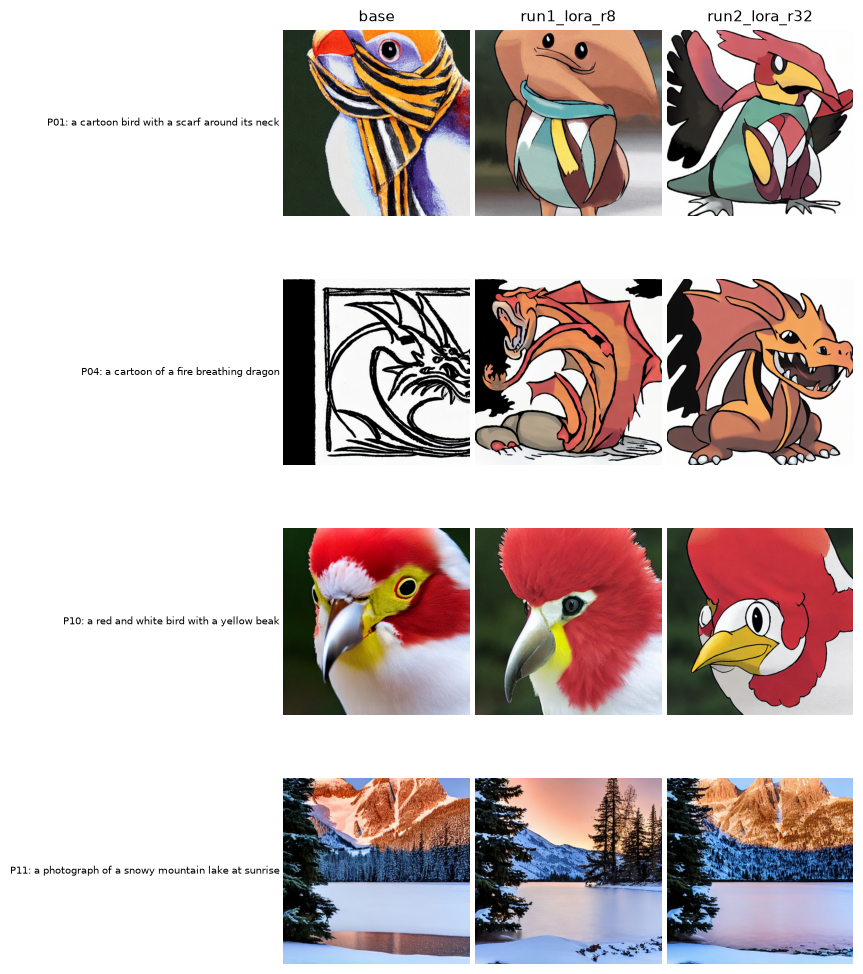

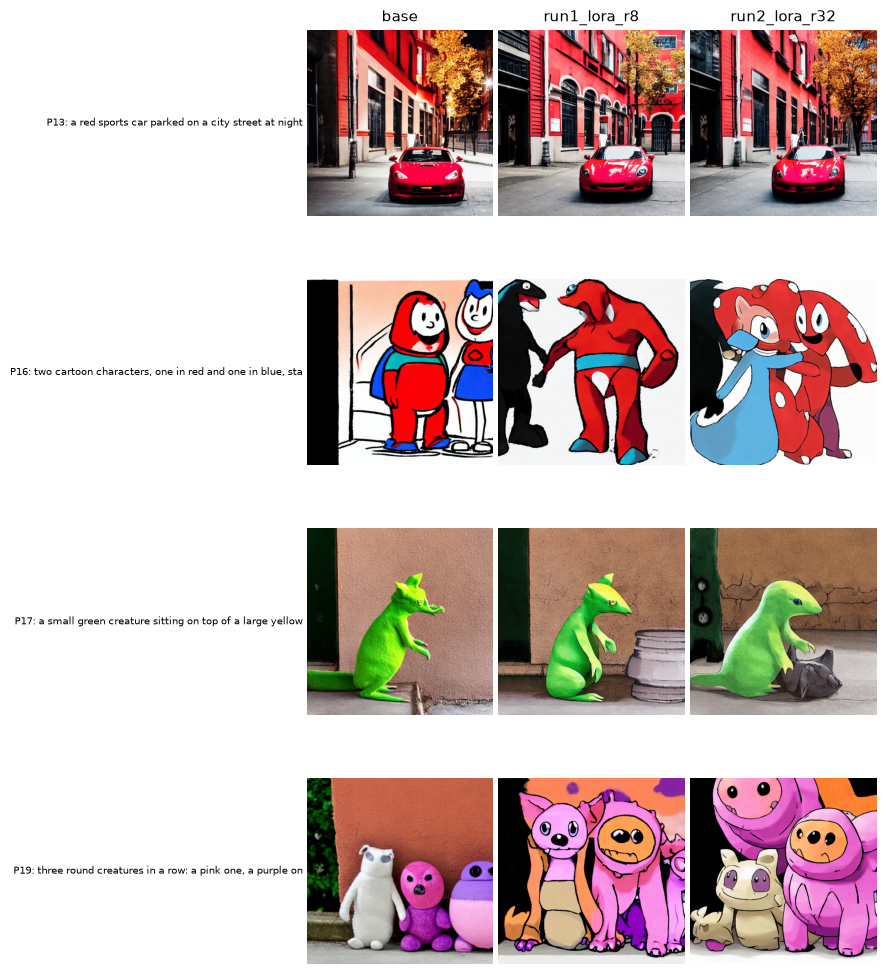

In [4]:
GRID_PROMPTS = ["P01", "P04", "P10", "P11", "P13", "P16", "P17", "P19"]
prompt_text = {p["id"]: p["prompt"] for p in prompts}


def show_grid(prompt_ids, file_name):
    figure, axes = plt.subplots(len(prompt_ids), 3, figsize=(9.5, 3.2 * len(prompt_ids)))
    for row, prompt_id in enumerate(prompt_ids):
        for column, model in enumerate(MODELS):
            axes[row, column].imshow(Image.open(GEN_DIR / model / f"{prompt_id}_s0.png"))
            axes[row, column].axis("off")
            if row == 0:
                axes[row, column].set_title(model, fontsize=11)
        axes[row, 0].text(-0.02, 0.5, f"{prompt_id}: " + prompt_text[prompt_id][:55], transform=axes[row, 0].transAxes,
                          ha="right", va="center", fontsize=7)
    plt.subplots_adjust(left=0.30, wspace=0.03, hspace=0.05)
    plt.savefig(GRID_DIR / file_name, dpi=110, bbox_inches="tight")
    plt.show()


show_grid(GRID_PROMPTS[:4], "side_by_side_1.png")
show_grid(GRID_PROMPTS[4:], "side_by_side_2.png")

## 4. CLIP score, KID and LPIPS diversity (task 2.4)

- **CLIP score** (prompt alignment): 100 x the cosine similarity between a generated image and its prompt in the CLIP (ViT-B/16) space, with negative values set to 0. Higher is better.
- **KID** (closeness to the dataset): Kernel Inception Distance between the 20 **in-domain** generated images of a model and the **83 test images**. Lower is better. KID is noisy with this few images (the subset size has to be 20), so only large differences mean something.
- **LPIPS diversity**: the LPIPS distance between the two seeds of the same prompt. Higher means more variety.

In [5]:
from transformers import CLIPModel, CLIPProcessor

CLIP_NAME = "openai/clip-vit-base-patch16"
clip = CLIPModel.from_pretrained(CLIP_NAME).to("cuda").eval()
clip_processor = CLIPProcessor.from_pretrained(CLIP_NAME)
print("CLIP logit scale (should be 100):", round(clip.logit_scale.exp().item(), 1))


def clip_scores(images, texts):
    """100 x cosine similarity between each image and its own prompt (at least 0)."""
    scores = []
    for start in range(0, len(images), 16):
        inputs = clip_processor(text=texts[start:start + 16], images=images[start:start + 16],
                                return_tensors="pt", padding=True, truncation=True, max_length=77).to("cuda")
        with torch.no_grad():
            output = clip(**inputs)
        # logits_per_image = logit_scale (100) x cosine similarity, and the diagonal is image i with prompt i
        scores += torch.diagonal(output.logits_per_image).float().clamp(min=0).cpu().tolist()
    return scores


generation_log["image"] = [Image.open(f) for f in generation_log["file"]]
generation_log["clip_score"] = clip_scores(list(generation_log["image"]), list(generation_log["prompt"]))

print(generation_log.groupby(["model", "prompt_type"])["clip_score"].mean().unstack().round(2).to_string())

CLIP logit scale (should be 100): 100.0


prompt_type    compositional  in_domain  out_of_domain
model                                                 
base                   33.29      33.36          31.29
run1_lora_r8           32.79      32.35          30.57
run2_lora_r32          33.04      32.17          31.14


In [6]:
from torchmetrics.image.kid import KernelInceptionDistance


def to_uint8_batch(images):
    return torch.stack([torch.from_numpy(np.asarray(i.convert("RGB").resize((SIZE, SIZE)))).permute(2, 0, 1) for i in images])


test_images = [Image.open(f) for f in sorted(TEST_DIR.glob("*.png"))]
real = to_uint8_batch(test_images)
print("Real images (test set):", len(real))

kid_results = {}
for model in MODELS:
    fake_images = list(generation_log[(generation_log["model"] == model) & (generation_log["prompt_type"] == "in_domain")]["image"])
    fake = to_uint8_batch(fake_images)

    torch.manual_seed(SEED)
    kid = KernelInceptionDistance(subset_size=len(fake), subsets=100, normalize=False).to("cuda")
    kid.update(real.to("cuda"), real=True)
    kid.update(fake.to("cuda"), real=False)
    mean, std = kid.compute()
    kid_results[model] = (float(mean), float(std))
    print(f"{model:15s} KID = {float(mean):.4f} +/- {float(std):.4f}   ({len(fake)} generated vs {len(real)} test images)")

C:\Users\tejas\AppData\Local\Temp\ipykernel_10604\900124668.py:5: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  return torch.stack([torch.from_numpy(np.asarray(i.convert("RGB").resize((SIZE, SIZE)))).permute(2, 0, 1) for i in images])


Real images (test set): 83


C:\Users\tejas\miniconda3\envs\data266_lab2_part2\Lib\site-packages\torchmetrics\utilities\prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


base            KID = 0.0947 +/- 0.0090   (20 generated vs 83 test images)


run1_lora_r8    KID = 0.0531 +/- 0.0065   (20 generated vs 83 test images)


run2_lora_r32   KID = 0.0356 +/- 0.0068   (20 generated vs 83 test images)


In [7]:
import lpips

lpips_model = lpips.LPIPS(net="alex", verbose=False).to("cuda")


def lpips_input(image):
    array = np.asarray(image.convert("RGB"), dtype=np.float32) / 127.5 - 1.0
    return torch.from_numpy(array).permute(2, 0, 1)[None].to("cuda")


diversity_rows = []
for model in MODELS:
    for p in prompts:
        pair = generation_log[(generation_log["model"] == model) & (generation_log["prompt_id"] == p["id"])].sort_values("seed")
        with torch.no_grad():
            distance = lpips_model(lpips_input(pair.iloc[0]["image"]), lpips_input(pair.iloc[1]["image"])).item()
        diversity_rows.append({"model": model, "prompt_id": p["id"], "prompt_type": p["type"], "lpips": distance})

diversity = pd.DataFrame(diversity_rows)
print(diversity.groupby(["model", "prompt_type"])["lpips"].mean().unstack().round(3).to_string())

C:\Users\tejas\miniconda3\envs\data266_lab2_part2\Lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\tejas\miniconda3\envs\data266_lab2_part2\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


prompt_type    compositional  in_domain  out_of_domain
model                                                 
base                   0.857      0.857          0.749
run1_lora_r8           0.788      0.779          0.731
run2_lora_r32          0.752      0.771          0.727


### Results per model

In [8]:
by_type = lambda frame, column: frame.groupby(["model", "prompt_type"])[column].mean().unstack()

clip_by_type = by_type(generation_log, "clip_score")
lpips_by_type = by_type(diversity, "lpips")

metrics = pd.DataFrame({
    "kid_mean": {m: kid_results[m][0] for m in MODELS},
    "kid_std": {m: kid_results[m][1] for m in MODELS},
    "clip_all": generation_log.groupby("model")["clip_score"].mean(),
    "clip_in_domain": clip_by_type["in_domain"],
    "clip_out_of_domain": clip_by_type["out_of_domain"],
    "clip_compositional": clip_by_type["compositional"],
    "lpips_all": diversity.groupby("model")["lpips"].mean(),
    "lpips_in_domain": lpips_by_type["in_domain"],
    "lpips_out_of_domain": lpips_by_type["out_of_domain"],
    "lpips_compositional": lpips_by_type["compositional"],
}).loc[MODELS]

metrics.round(4).to_csv(METRIC_DIR / "metrics_by_model.csv")
generation_log.drop(columns="image").to_csv(METRIC_DIR / "per_image_metrics.csv", index=False)
diversity.to_csv(METRIC_DIR / "diversity_per_prompt.csv", index=False)
print(metrics.round(4).T.to_string())

                        base  run1_lora_r8  run2_lora_r32
kid_mean              0.0947        0.0531         0.0356
kid_std               0.0090        0.0065         0.0068
clip_all             32.8247       32.0135        32.1311
clip_in_domain       33.3616       32.3457        32.1726
clip_out_of_domain   31.2872       30.5693        31.1396
clip_compositional   33.2884       32.7931        33.0398
lpips_all             0.8301        0.7694         0.7551
lpips_in_domain       0.8570        0.7794         0.7711
lpips_out_of_domain   0.7493        0.7308         0.7266
lpips_compositional   0.8571        0.7880         0.7517


## 5. Choose the final run

The task is domain-specific generation, so the final run is the run whose in-domain images are **closest to the test images** (lowest KID). The CLIP score and the diversity are then checked to see what that choice costs.

In [9]:
FINAL_RUN = metrics.loc[RUN_NAMES, "kid_mean"].idxmin()
OTHER_RUN = [r for r in RUN_NAMES if r != FINAL_RUN][0]

print("Final run:", FINAL_RUN)
for run in RUN_NAMES:
    row = metrics.loc[run]
    print(f"  {run:15s} KID {row['kid_mean']:.4f} | CLIP {row['clip_all']:.2f} "
          f"(in-domain {row['clip_in_domain']:.2f}, other {row['clip_out_of_domain']:.2f}/{row['clip_compositional']:.2f}) | LPIPS {row['lpips_all']:.3f}")
print(f"  {'base':15s} KID {metrics.loc['base', 'kid_mean']:.4f} | CLIP {metrics.loc['base', 'clip_all']:.2f} | LPIPS {metrics.loc['base', 'lpips_all']:.3f}")

Final run: run2_lora_r32
  run1_lora_r8    KID 0.0531 | CLIP 32.01 (in-domain 32.35, other 30.57/32.79) | LPIPS 0.769
  run2_lora_r32   KID 0.0356 | CLIP 32.13 (in-domain 32.17, other 31.14/33.04) | LPIPS 0.755
  base            KID 0.0947 | CLIP 32.82 | LPIPS 0.830


## 6. Failure modes (with example images)

The examples are picked by the numbers, not by hand:

1. **Out-of-domain prompt:** the prompt where the final run's CLIP score drops the most compared with the base model.
2. **Compositional prompt:** the compositional prompt with the lowest CLIP score for the final run.
3. **Least diverse prompt:** the prompt where the final run's two seeds look most alike (lowest LPIPS). This checks for repeated outputs.

1. Out-of-domain: P13 - CLIP base 31.9 -> final 29.3
2. Compositional: P19 - CLIP final 30.2 (base 30.0)
3. Least diverse: P19 - LPIPS between the two seeds 0.661 (average of the final run: 0.755)


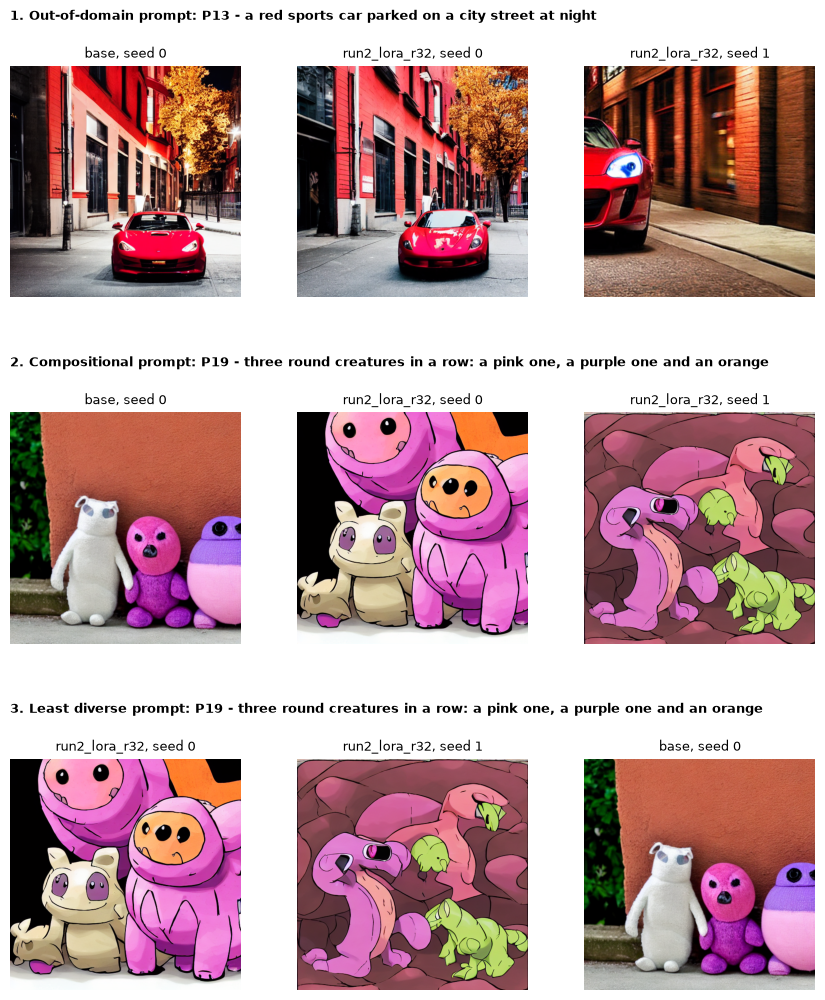

In [10]:
per_prompt_clip = generation_log.groupby(["model", "prompt_id"])["clip_score"].mean().unstack(0)
types = {p["id"]: p["type"] for p in prompts}

ood_ids = [i for i in per_prompt_clip.index if types[i] == "out_of_domain"]
comp_ids = [i for i in per_prompt_clip.index if types[i] == "compositional"]
ood_drop = (per_prompt_clip.loc[ood_ids, "base"] - per_prompt_clip.loc[ood_ids, FINAL_RUN]).sort_values(ascending=False)
failure_ood = ood_drop.index[0]
failure_comp = per_prompt_clip.loc[comp_ids, FINAL_RUN].idxmin()
final_diversity = diversity[diversity["model"] == FINAL_RUN].set_index("prompt_id")["lpips"]
failure_repeat = final_diversity.idxmin()

print(f"1. Out-of-domain: {failure_ood} - CLIP base {per_prompt_clip.loc[failure_ood, 'base']:.1f} -> final {per_prompt_clip.loc[failure_ood, FINAL_RUN]:.1f}")
print(f"2. Compositional: {failure_comp} - CLIP final {per_prompt_clip.loc[failure_comp, FINAL_RUN]:.1f} (base {per_prompt_clip.loc[failure_comp, 'base']:.1f})")
print(f"3. Least diverse: {failure_repeat} - LPIPS between the two seeds {final_diversity[failure_repeat]:.3f} (average of the final run: {final_diversity.mean():.3f})")

figure, axes = plt.subplots(3, 3, figsize=(10.5, 12))
rows = [
    (failure_ood, [("base", 0), (FINAL_RUN, 0), (FINAL_RUN, 1)], "1. Out-of-domain prompt"),
    (failure_comp, [("base", 0), (FINAL_RUN, 0), (FINAL_RUN, 1)], "2. Compositional prompt"),
    (failure_repeat, [(FINAL_RUN, 0), (FINAL_RUN, 1), ("base", 0)], "3. Least diverse prompt"),
]
for row, (prompt_id, cells, title) in enumerate(rows):
    for column, (model, seed) in enumerate(cells):
        axes[row, column].imshow(Image.open(GEN_DIR / model / f"{prompt_id}_s{seed}.png"))
        axes[row, column].set_title(f"{model}, seed {seed}", fontsize=9)
        axes[row, column].axis("off")
    axes[row, 0].text(0, 1.2, f"{title}: {prompt_id} - {prompt_text[prompt_id][:70]}", transform=axes[row, 0].transAxes, fontsize=9, fontweight="bold")
plt.subplots_adjust(hspace=0.5)
plt.savefig(GRID_DIR / "failure_modes.png", dpi=110, bbox_inches="tight")
plt.show()

### What the images show (our notes on the images of this run)

1. **Out-of-domain prompts: no style leaks, but parts of the prompt are still ignored.** The mountain lake and the sports car look almost the same with the base model and with both LoRA runs, so the fine-tuning did not push the Pokemon style into unrelated prompts. With seed 0 all three models draw the car in daylight, so "at night" is ignored. This is a weakness of the base model that the fine-tuning does not fix. The CLIP drop for this prompt is not explained by a style change (the images stay photographs); seed 1 simply shows a different, closer view of the car.
2. **Compositional prompts: all models fail, and the fine-tuned ones lose some ability.** For "three round creatures in a row: a pink one, a purple one and an orange one", the base model draws three plush toys in a row but with partly wrong colours (white, pink and purple, no orange), and the final run draws a pink group that is not a clean row (seed 0) and a different scene (seed 1). For "two cartoon characters, one in red and one in blue" (grid above) the base model gets two clear figures in red and blue, `run1_lora_r8` swaps the blue figure for a black one, and `run2_lora_r32` keeps red and blue but the two characters run into each other. The simple colour-and-animal captions of the dataset do not teach counting, colour assignment or arrangement. CLIP scores hardly move for these prompts (see the table), so CLIP does not catch these errors.
3. **No sign of repeated outputs.** Even for the least diverse prompt, the two seeds give clearly different pictures. The lower LPIPS of the LoRA runs mostly comes from the shared look (white background, thick outlines) and not from the model repeating itself.

## 7. Safety (C4): NSFW filter and memorization check

**License.** The dataset (`cc-by-nc-sa-4.0`) and the characters are copyrighted, so the models and the generated images are for non-commercial research only. The Stable Diffusion 1.5 weights use the CreativeML OpenRAIL-M license.

**NSFW filter.** The safety checker of Stable Diffusion (`CompVis/stable-diffusion-safety-checker`) is run on all generated images.

Images checked: 120
Flagged as NSFW per model: {'base': 1, 'run1_lora_r8': 2, 'run2_lora_r32': 6}
Total flagged: 9


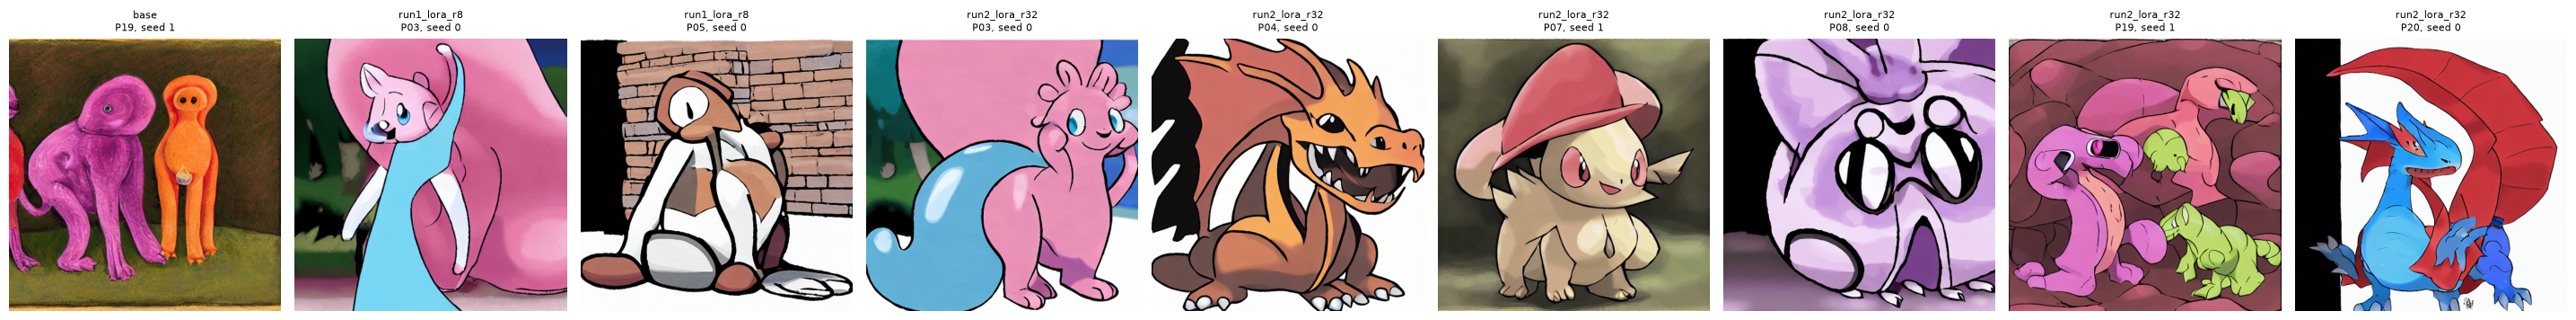

In [11]:
from diffusers.pipelines.stable_diffusion.safety_checker import StableDiffusionSafetyChecker
from transformers import CLIPImageProcessor

from diffusers.utils import logging as diffusers_logging
diffusers_logging.set_verbosity_error()        # the checker prints one long warning for every flagged image

SAFETY_NAME = "CompVis/stable-diffusion-safety-checker"
safety_checker = StableDiffusionSafetyChecker.from_pretrained(SAFETY_NAME).to("cuda", dtype=torch.float16).eval()
safety_extractor = CLIPImageProcessor.from_pretrained(SAFETY_NAME)

flags = []
files = list(generation_log["file"])
for start in range(0, len(files), 8):
    pictures = [Image.open(f).convert("RGB") for f in files[start:start + 8]]
    clip_input = safety_extractor(pictures, return_tensors="pt").pixel_values.to("cuda", dtype=torch.float16)
    arrays = np.stack([np.asarray(p, dtype=np.float32) / 255.0 for p in pictures])
    with torch.no_grad():
        _, has_nsfw = safety_checker(clip_input=clip_input, images=arrays)
    flags += [bool(x) for x in has_nsfw]

nsfw = generation_log.drop(columns="image").assign(flagged_nsfw=flags)
nsfw[["model", "prompt_id", "seed", "flagged_nsfw"]].to_csv(SAFETY_DIR / "nsfw_check.csv", index=False)

print("Images checked:", len(nsfw))
print("Flagged as NSFW per model:", nsfw.groupby("model")["flagged_nsfw"].sum().astype(int).to_dict())
print("Total flagged:", int(nsfw["flagged_nsfw"].sum()))
del safety_checker
torch.cuda.empty_cache()

# look at every flagged image
flagged = nsfw[nsfw["flagged_nsfw"]]
if len(flagged):
    figure, axes = plt.subplots(1, len(flagged), figsize=(3.2 * len(flagged), 3.6), squeeze=False)
    for axis, (_, row) in zip(axes[0], flagged.iterrows()):
        axis.imshow(Image.open(row["file"]))
        axis.set_title(f"{row['model']}\n{row['prompt_id']}, seed {row['seed']}", fontsize=8)
        axis.axis("off")
    plt.tight_layout()
    plt.savefig(GRID_DIR / "nsfw_flagged.png", dpi=100)
    plt.show()

**Result of the NSFW check (our notes on this run).** We looked at every flagged image above. All of them show harmless cartoon creatures, so these are false alarms. The Stable Diffusion safety checker is known to flag some drawings with flat pastel or skin-like colours. Nothing had to be removed. The checker flagged the rank-32 run most often, which fits its stronger flat-colour style.

**Memorization check.** For the 10 in-domain images of the final run (seed 0), the most similar **training** image is found with CLIP image embeddings. The 3 closest pairs are shown. For context, the same measure is computed for the base model and for the held-out **test** images: a test image is new to the model, so its similarity to the closest training image shows what "not copied" looks like. If the final run's images were copies, their similarity would be much higher than that.

Similarity of an image to its most similar training image (CLIP cosine, 1.0 = identical):
  final run, 10 in-domain images: mean 0.885, max 0.937
  base model, same 10 prompts:    mean 0.746, max 0.842
  83 unseen test images:      mean 0.933, max 0.978

prompt_id                                              prompt most_similar_training_image  clip_similarity
      P01         a cartoon bird with a scarf around its neck            pokemon_0776.png           0.9375
      P05 a cartoon character sitting in the middle of a pose            pokemon_0570.png           0.9197
      P09               a cartoon bird with a hat on its head            pokemon_0374.png           0.9172
      P04                a cartoon of a fire breathing dragon            pokemon_0628.png           0.9069
      P07       a very cute looking pokemon with a big hat on            pokemon_0524.png           0.9044
      P03           a pink cartoon character with a blue tail            pokemon_0065.png           0.8

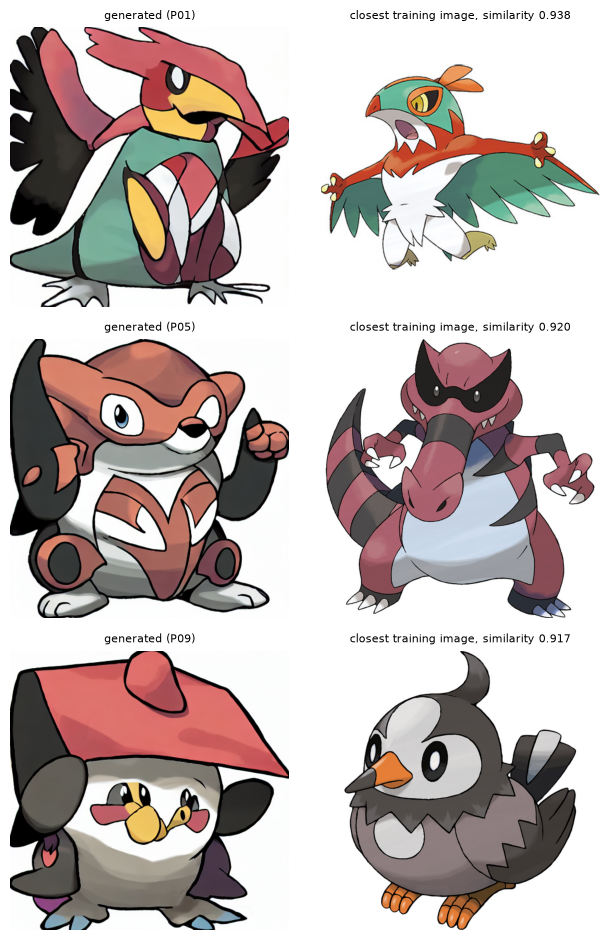

In [12]:
def clip_image_embeddings(images):
    embeddings = []
    for start in range(0, len(images), 32):
        pixels = clip_processor(images=images[start:start + 32], return_tensors="pt")["pixel_values"].to("cuda")
        with torch.no_grad():
            pooled = clip.vision_model(pixel_values=pixels).pooler_output
            embedding = clip.visual_projection(pooled)
        embeddings.append(torch.nn.functional.normalize(embedding.float(), dim=-1).cpu())
    return torch.cat(embeddings)


train_files = sorted(TRAIN_DIR.glob("*.png"))
train_embeddings = clip_image_embeddings([Image.open(f) for f in train_files])


def nearest_training_image(images):
    similarity = clip_image_embeddings(images) @ train_embeddings.T
    best_value, best_index = similarity.max(dim=1)
    return best_value.numpy(), best_index.numpy()


in_domain_ids = [p["id"] for p in prompts if p["type"] == "in_domain"]
memorization = {}
for model in [FINAL_RUN, "base"]:
    generated = [Image.open(GEN_DIR / model / f"{i}_s0.png") for i in in_domain_ids]
    memorization[model] = nearest_training_image(generated)

test_values, _ = nearest_training_image(test_images)

print("Similarity of an image to its most similar training image (CLIP cosine, 1.0 = identical):")
print(f"  final run, 10 in-domain images: mean {memorization[FINAL_RUN][0].mean():.3f}, max {memorization[FINAL_RUN][0].max():.3f}")
print(f"  base model, same 10 prompts:    mean {memorization['base'][0].mean():.3f}, max {memorization['base'][0].max():.3f}")
print(f"  {len(test_images)} unseen test images:      mean {test_values.mean():.3f}, max {test_values.max():.3f}")

values, indexes = memorization[FINAL_RUN]
memorization_table = pd.DataFrame({
    "prompt_id": in_domain_ids,
    "prompt": [prompt_text[i] for i in in_domain_ids],
    "most_similar_training_image": [train_files[i].name for i in indexes],
    "clip_similarity": values.round(4),
}).sort_values("clip_similarity", ascending=False)
memorization_table.to_csv(SAFETY_DIR / "memorization_check.csv", index=False)
print()
print(memorization_table.to_string(index=False))

# the 3 closest pairs
top = memorization_table.head(3)
figure, axes = plt.subplots(3, 2, figsize=(6.5, 9.5))
for row, (_, entry) in enumerate(top.iterrows()):
    axes[row, 0].imshow(Image.open(GEN_DIR / FINAL_RUN / f"{entry['prompt_id']}_s0.png"))
    axes[row, 0].set_title(f"generated ({entry['prompt_id']})", fontsize=8)
    axes[row, 1].imshow(Image.open(TRAIN_DIR / entry["most_similar_training_image"]))
    axes[row, 1].set_title(f"closest training image, similarity {entry['clip_similarity']:.3f}", fontsize=8)
    axes[row, 0].axis("off")
    axes[row, 1].axis("off")
plt.tight_layout()
plt.savefig(GRID_DIR / "memorization_pairs.png", dpi=110)
plt.show()

## 8. Blinded human evaluation (final run vs base model)

Raters compare **25 image pairs**: the same prompt and seed, one image from the base model and one from the final run, with left and right randomized. For each pair a rater picks the better image for

1. **domain style** (does it look like the flat, official-artwork cartoon style of the dataset?), and
2. **prompt match** (does it show what the prompt says?).

The raters do not know which image is which. At least 3 raters are needed (both team members and one person outside the team).

This cell writes a **single web page** (`outputs/part2/human_eval/rating_form.html`, works offline in any browser). Each rater opens it, fills it in and clicks *Download my ratings*. The downloaded file goes into `outputs/part2/human_eval/ratings/`. The cell after next reads all rating files and computes the win rate.

In [13]:
rng = random.Random(SEED)
combinations = [(p["id"], seed) for p in prompts for seed in SEEDS]
chosen = rng.sample(combinations, 25)

pair_rows, form_pairs = [], []
for number, (prompt_id, seed) in enumerate(chosen, start=1):
    final_left = rng.random() < 0.5                       # randomize left/right
    left_model, right_model = (FINAL_RUN, "base") if final_left else ("base", FINAL_RUN)
    left = Image.open(GEN_DIR / left_model / f"{prompt_id}_s{seed}.png").convert("RGB")
    right = Image.open(GEN_DIR / right_model / f"{prompt_id}_s{seed}.png").convert("RGB")

    pair = Image.new("RGB", (SIZE * 2 + 16, SIZE), (255, 255, 255))
    pair.paste(left, (0, 0))
    pair.paste(right, (SIZE + 16, 0))
    pair.save(HUMAN_DIR / "pairs" / f"pair_{number:02d}.png")

    buffer = io.BytesIO()
    pair.save(buffer, format="JPEG", quality=85)
    form_pairs.append({
        "id": f"pair_{number:02d}",
        "prompt": prompt_text[prompt_id],
        "image": "data:image/jpeg;base64," + base64.b64encode(buffer.getvalue()).decode(),
    })
    pair_rows.append({"pair_id": f"pair_{number:02d}", "prompt_id": prompt_id, "seed": seed,
                      "left_model": left_model, "right_model": right_model})

answer_key = pd.DataFrame(pair_rows)
answer_key.to_csv(HUMAN_DIR / "answer_key.csv", index=False)       # do NOT show this file to the raters

FORM_TEMPLATE = """<!DOCTYPE html>
<html lang="en"><head><meta charset="utf-8"><title>Image comparison</title>
<style>
 body { font-family: Arial, sans-serif; max-width: 1100px; margin: 20px auto; padding: 0 12px; }
 .pair { border: 1px solid #ccc; border-radius: 6px; padding: 10px; margin: 18px 0; }
 img { width: 100%; }
 .q { margin: 6px 0; } label { margin-right: 18px; }
 button { font-size: 16px; padding: 8px 16px; }
</style></head><body>
<h2>Which image is better?</h2>
<p>Each page below shows two images made from the same prompt. For each pair, choose the <b>left</b> or the <b>right</b> image for:</p>
<ol><li><b>Domain style</b>: which one looks more like flat, clean cartoon artwork of a single character on a white background?</li>
<li><b>Prompt match</b>: which one shows better what the prompt describes?</li></ol>
<p>You do not know which image comes from which model. Pick the one you prefer even if the difference is small.</p>
<p>Your name: <input id="rater" placeholder="for example anna"></p>
<div id="pairs"></div>
<p><button onclick="download()">Download my ratings</button> <span id="status"></span></p>
<script>
var PAIRS = __PAIRS__;
var holder = document.getElementById("pairs");
PAIRS.forEach(function(p, i) {
  var d = document.createElement("div"); d.className = "pair";
  d.innerHTML = "<b>" + (i + 1) + " of " + PAIRS.length + "</b> - prompt: <i>" + p.prompt + "</i><img src='" + p.image + "'>" +
    "<div class='q'>1. Domain style: <label><input type='radio' name='style_" + p.id + "' value='left'> left</label>" +
    "<label><input type='radio' name='style_" + p.id + "' value='right'> right</label></div>" +
    "<div class='q'>2. Prompt match: <label><input type='radio' name='prompt_" + p.id + "' value='left'> left</label>" +
    "<label><input type='radio' name='prompt_" + p.id + "' value='right'> right</label></div>";
  holder.appendChild(d);
});
function chosen(name) {
  var r = document.querySelector("input[name='" + name + "']:checked");
  return r ? r.value : "";
}
function download() {
  var rater = document.getElementById("rater").value.trim().replace(/[^a-zA-Z0-9_-]/g, "");
  if (!rater) { alert("Please type your name first."); return; }
  var lines = ["rater,pair_id,style_choice,prompt_choice"], missing = 0;
  PAIRS.forEach(function(p) {
    var s = chosen("style_" + p.id), q = chosen("prompt_" + p.id);
    if (!s || !q) { missing++; }
    lines.push([rater, p.id, s, q].join(","));
  });
  if (missing > 0 && !confirm(missing + " pairs are not fully answered. Download anyway?")) { return; }
  var blob = new Blob([lines.join("\\n") + "\\n"], {type: "text/csv"});
  var a = document.createElement("a"); a.href = URL.createObjectURL(blob);
  a.download = "ratings_" + rater + ".csv"; a.click();
  document.getElementById("status").textContent = "Saved as ratings_" + rater + ".csv - send this file back.";
}
</script></body></html>"""

form_path = HUMAN_DIR / "rating_form.html"
form_path.write_text(FORM_TEMPLATE.replace("__PAIRS__", json.dumps(form_pairs)), encoding="utf-8")

print("Pairs:", len(answer_key), "| final run on the left in", int((answer_key["left_model"] == FINAL_RUN).sum()), "pairs")
print("Rating form:", form_path.resolve(), f"({form_path.stat().st_size / 1e6:.1f} MB)")
print("Answer key: ", (HUMAN_DIR / "answer_key.csv").resolve(), "(keep it away from the raters)")

Pairs: 25 | final run on the left in 15 pairs
Rating form: C:\Users\tejas\Desktop\GPU_LAB_2\outputs\part2\human_eval\rating_form.html (4.0 MB)
Answer key:  C:\Users\tejas\Desktop\GPU_LAB_2\outputs\part2\human_eval\answer_key.csv (keep it away from the raters)


### Win rate of the final run over the base model

Reads every `ratings_*.csv` in `outputs/part2/human_eval/ratings/`. A *win* means the rater picked the image of the final run.

In [14]:
rating_files = sorted((HUMAN_DIR / "ratings").glob("ratings_*.csv"))
human_results = {"raters": 0, "style_win_rate": None, "prompt_win_rate": None, "agreement": None}

if not rating_files:
    print("No rating files yet. Send outputs/part2/human_eval/rating_form.html to at least 3 raters")
    print("(both team members and one person outside the team), put their ratings_*.csv files into")
    print("outputs/part2/human_eval/ratings/ and run this cell again.")
else:
    ratings = pd.concat([pd.read_csv(f, dtype=str, keep_default_na=False) for f in rating_files], ignore_index=True)
    ratings = ratings.merge(answer_key, on="pair_id")
    for criterion in ["style", "prompt"]:
        choice = ratings[f"{criterion}_choice"]
        chosen_model = np.where(choice == "left", ratings["left_model"], np.where(choice == "right", ratings["right_model"], ""))
        ratings[f"{criterion}_win"] = np.where(chosen_model == "", np.nan, (chosen_model == FINAL_RUN).astype(float))

    per_rater = ratings.groupby("rater")[["style_win", "prompt_win"]].mean().round(3)
    print("Win rate of", FINAL_RUN, "against the base model, per rater:")
    print(per_rater.to_string())

    # how often two raters made the same choice on the same pair
    agreement = []
    raters = list(ratings["rater"].unique())
    for i in range(len(raters)):
        for j in range(i + 1, len(raters)):
            a = ratings[ratings["rater"] == raters[i]].set_index("pair_id")
            b = ratings[ratings["rater"] == raters[j]].set_index("pair_id")
            for criterion in ["style_win", "prompt_win"]:
                both = pd.concat([a[criterion], b[criterion]], axis=1, join="inner").dropna()
                agreement += list((both.iloc[:, 0] == both.iloc[:, 1]).astype(float))

    human_results = {
        "raters": len(raters),
        "style_win_rate": round(float(ratings["style_win"].mean()), 3),
        "prompt_win_rate": round(float(ratings["prompt_win"].mean()), 3),
        "agreement": round(float(np.mean(agreement)), 3) if agreement else None,
    }
    print("\nAll raters together:", human_results)
    if len(raters) < 3:
        print("Only", len(raters), "rater(s) so far - the lab needs at least 3 (both team members and one person outside the team).")

No rating files yet. Send outputs/part2/human_eval/rating_form.html to at least 3 raters
(both team members and one person outside the team), put their ratings_*.csv files into
outputs/part2/human_eval/ratings/ and run this cell again.


## 9. Results table (one table for Part 2)

**Base model** is the baseline, **final run** is the system. Both LoRA runs are shown.

In [15]:
results = pd.DataFrame({
    "role": ["baseline" if m == "base" else ("FINAL" if m == FINAL_RUN else "other run") for m in MODELS],
    "KID (in-domain, lower is better)": [f"{kid_results[m][0]:.4f} +/- {kid_results[m][1]:.4f}" for m in MODELS],
    "CLIP score (all 40 images)": [round(metrics.loc[m, "clip_all"], 2) for m in MODELS],
    "LPIPS diversity": [round(metrics.loc[m, "lpips_all"], 3) for m in MODELS],
    "human win rate vs base (style / prompt)": [
        "-" if m != FINAL_RUN else (
            "pending ratings" if human_results["style_win_rate"] is None
            else f"{human_results['style_win_rate']:.2f} / {human_results['prompt_win_rate']:.2f} ({human_results['raters']} raters)")
        for m in MODELS],
    "training GPU-hours": ["-"] + [training_table.loc[r, "gpu_hours"] for r in RUN_NAMES],
    "peak GPU memory (GB)": ["-"] + [training_table.loc[r, "peak_gpu_memory_gb"] for r in RUN_NAMES],
}, index=MODELS)

results.to_csv(METRIC_DIR / "results_table.csv")
print(results.T.to_string())

                                                      base       run1_lora_r8      run2_lora_r32
role                                              baseline          other run              FINAL
KID (in-domain, lower is better)         0.0947 +/- 0.0090  0.0531 +/- 0.0065  0.0356 +/- 0.0068
CLIP score (all 40 images)                           32.82              32.01              32.13
LPIPS diversity                                       0.83              0.769              0.755
human win rate vs base (style / prompt)                  -                  -    pending ratings
training GPU-hours                                       -              0.271              0.269
peak GPU memory (GB)                                     -                3.7               3.75


## 10. Which run would we choose, and why

In [16]:
final, other, base = metrics.loc[FINAL_RUN], metrics.loc[OTHER_RUN], metrics.loc["base"]
print(f"Chosen: {FINAL_RUN}.")
print(f"- Closeness to the dataset: KID {final['kid_mean']:.4f} (base {base['kid_mean']:.4f}, other run {other['kid_mean']:.4f}).")
print(f"- Prompt alignment: CLIP {final['clip_all']:.2f} overall; in-domain {final['clip_in_domain']:.2f} vs base {base['clip_in_domain']:.2f}; "
      f"out-of-domain {final['clip_out_of_domain']:.2f} vs base {base['clip_out_of_domain']:.2f}; "
      f"compositional {final['clip_compositional']:.2f} vs base {base['clip_compositional']:.2f}.")
print(f"- Diversity: LPIPS {final['lpips_all']:.3f} (base {base['lpips_all']:.3f}, other run {other['lpips_all']:.3f}).")
print(f"- Cost: {training_table.loc[FINAL_RUN, 'gpu_hours']} GPU-hours and {training_table.loc[FINAL_RUN, 'peak_gpu_memory_gb']} GB peak memory "
      f"({training_table.loc[FINAL_RUN, 'trainable_parameters']:,} trainable parameters), against "
      f"{training_table.loc[OTHER_RUN, 'gpu_hours']} GPU-hours, {training_table.loc[OTHER_RUN, 'peak_gpu_memory_gb']} GB and "
      f"{training_table.loc[OTHER_RUN, 'trainable_parameters']:,} parameters for {OTHER_RUN}.")

print()
print("What worked and what did not (numbers from the tables above):")
print(f"+ Both LoRA runs moved the images towards the dataset: KID {base['kid_mean']:.3f} (base) -> {other['kid_mean']:.3f} ({OTHER_RUN}) -> {final['kid_mean']:.3f} ({FINAL_RUN}).")
print(f"+ The change stays inside the domain: the out-of-domain CLIP score only moves from {base['clip_out_of_domain']:.2f} (base) to {final['clip_out_of_domain']:.2f}.")
print(f"- Prompt alignment on in-domain prompts got worse: CLIP {base['clip_in_domain']:.2f} (base) -> {final['clip_in_domain']:.2f}. "
      "The model draws a stylised creature, and the weak BLIP captions give it little to follow.")
print(f"- Diversity went down: LPIPS {base['lpips_all']:.3f} (base) -> {final['lpips_all']:.3f}.")
print(f"- {FINAL_RUN} versus {OTHER_RUN}: the KID is {other['kid_mean'] - final['kid_mean']:.3f} lower, the CLIP score differs by "
      f"{final['clip_all'] - other['clip_all']:+.2f}, and the training cost is almost the same.")
print("- KID is computed from only 20 generated images and its spread over the 100 subsets is about "
      f"{kid_results[FINAL_RUN][1]:.3f}, so it is only a rough guide.")

Chosen: run2_lora_r32.
- Closeness to the dataset: KID 0.0356 (base 0.0947, other run 0.0531).
- Prompt alignment: CLIP 32.13 overall; in-domain 32.17 vs base 33.36; out-of-domain 31.14 vs base 31.29; compositional 33.04 vs base 33.29.
- Diversity: LPIPS 0.755 (base 0.830, other run 0.769).
- Cost: 0.269 GPU-hours and 3.75 GB peak memory (6,377,472 trainable parameters), against 0.271 GPU-hours, 3.7 GB and 1,594,368 parameters for run1_lora_r8.

What worked and what did not (numbers from the tables above):
+ Both LoRA runs moved the images towards the dataset: KID 0.095 (base) -> 0.053 (run1_lora_r8) -> 0.036 (run2_lora_r32).
+ The change stays inside the domain: the out-of-domain CLIP score only moves from 31.29 (base) to 31.14.
- Prompt alignment on in-domain prompts got worse: CLIP 33.36 (base) -> 32.17. The model draws a stylised creature, and the weak BLIP captions give it little to follow.
- Diversity went down: LPIPS 0.830 (base) -> 0.755.
- run2_lora_r32 versus run1_lora_r8: th

**Decision (written for the run shown above, where the final run is `run2_lora_r32`).** We choose the run with the lowest KID, and the images agree with the numbers: in the grids `run2_lora_r32` turns in-domain prompts into flat, outlined cartoon creatures on a white background, while `run1_lora_r8` is closer to the base model and often keeps a photographic or painted background. The cost is practically the same (same steps and batch size, almost the same time and memory), but the rank-32 adapter has four times as many parameters (6.4 million against 1.6 million, so a larger file). The price of choosing it is a small loss in prompt alignment and diversity compared with the base model, which both fine-tuned runs show. If the notebook is run again and a different run wins, this paragraph has to be checked against the numbers.

## 11. Upload to Hugging Face

- **Models:** both LoRA files with a model card (the card of the final run is the full one). Repositories `SawantTej/pokemon-sd15-lora-r8` and `SawantTej/pokemon-sd15-lora-r32`.
- **Dataset:** all 120 generated images with prompt, seed and model in the metadata (`SawantTej/pokemon-sd15-lora-generations`).

Model files and images are not stored in GitHub.

In [17]:
from huggingface_hub import HfApi

REPO_IDS = {"run1_lora_r8": f"{HF_USER}/pokemon-sd15-lora-r8", "run2_lora_r32": f"{HF_USER}/pokemon-sd15-lora-r32"}
DATASET_ID = f"{HF_USER}/pokemon-sd15-lora-generations"


def model_card(run):
    row, tt = metrics.loc[run], training_table.loc[run]
    is_final = run == FINAL_RUN
    human_line = ("not available yet" if human_results["style_win_rate"] is None else
                  f"{human_results['style_win_rate']:.2f} (style) and {human_results['prompt_win_rate']:.2f} (prompt match) "
                  f"against the base model, {human_results['raters']} raters")
    return f"""---
license: creativeml-openrail-m
base_model: {BASE_MODEL}
library_name: diffusers
tags:
- stable-diffusion
- text-to-image
- lora
- diffusers
datasets:
- reach-vb/pokemon-blip-captions
---

# Pokemon LoRA for Stable Diffusion 1.5 (rank {int(tt['rank'])}){' - selected as the final model' if is_final else ' - not selected as the final model'}

A LoRA adapter for `{BASE_MODEL}`, fine-tuned on Pokemon artwork with BLIP captions. It is one of two runs of DATA 266 Lab 2 (rank 8 and rank 32, same data and steps).
{'**This is the run we selected as final**, because its in-domain images are closest to the test images (lowest KID).' if is_final else 'The other run (rank ' + str(int(training_table.loc[FINAL_RUN, 'rank'])) + ') was selected as the final model.'}

## Usage

```python
import torch
from diffusers import StableDiffusionPipeline
pipe = StableDiffusionPipeline.from_pretrained("{BASE_MODEL}", torch_dtype=torch.float16).to("cuda")
pipe.load_lora_weights("{REPO_IDS[run]}")
image = pipe("a cartoon bird with a hat on its head", num_inference_steps=30).images[0]
```

## Training data
`reach-vb/pokemon-blip-captions` (license cc-by-nc-sa-4.0), 833 images. After removing duplicates: 830 images. Split 90/10 with seed 266: 747 training images (this model) and 83 test images (only used for evaluation). Images are 512x512.

## Training settings
LoRA on the attention layers of the UNet, rank {int(tt['rank'])} ({int(tt['trainable_parameters']):,} trainable parameters), learning rate {tt['learning_rate']} (cosine schedule), {int(tt['steps'])} steps, batch size {int(tt['batch_size'])} (about {tt['epochs']} epochs), fp16 mixed precision, seed 266, trained with the diffusers `train_text_to_image_lora.py` script on one RTX 4090 (peak GPU memory {tt['peak_gpu_memory_gb']} GB, {tt['training_minutes']} minutes).

## Results (our evaluation, 20 prompts x 2 seeds, 30 steps, guidance {GUIDANCE})
- KID against the 83 test images (20 in-domain generations): {row['kid_mean']:.4f} (base model: {base['kid_mean']:.4f}).
- CLIP score: {row['clip_all']:.2f} on all prompts (base model: {base['clip_all']:.2f}).
- LPIPS diversity between two seeds: {row['lpips_all']:.3f} (base model: {base['lpips_all']:.3f}).
- Human comparison with the base model: {human_line if is_final else 'only done for the final run'}.

## Limitations
- The training set is small and very uniform (single characters on a white background). The style may carry over to unrelated prompts (we did not see this on our 5 out-of-domain test prompts), and prompts with several objects, counts or colours often go wrong.
- The captions were written by a model (BLIP) and many do not match the pictures.
- KID is computed on only 20 generated images, so small differences are not meaningful.
- The generated images were checked with the Stable Diffusion safety checker: {int(nsfw['flagged_nsfw'].sum())} of {len(nsfw)} images were flagged. We looked at all of them: they are harmless cartoon creatures (false alarms of the checker).

## License and intended use
The Pokemon characters are copyrighted and the training data is licensed cc-by-nc-sa-4.0, so this model and its images are for **non-commercial research and education only**. The base model is under the CreativeML OpenRAIL-M license, which also applies to this adapter.
"""


dataset_card = f"""---
license: cc-by-nc-sa-4.0
task_categories:
- text-to-image
tags:
- stable-diffusion
- lora
---

# Images generated for DATA 266 Lab 2 (Part 2)

120 images: 20 fixed prompts x 2 seeds (0 and 1) x 3 models (`base` = Stable Diffusion 1.5, `run1_lora_r8`, `run2_lora_r32`). All models use the same sampler ({generation_log['sampler'].iloc[0]}), {STEPS} steps, guidance {GUIDANCE}, 512x512.
`metadata.jsonl` has the prompt, prompt type (in_domain, out_of_domain, compositional), seed and model of every image.
The LoRA models are in `{REPO_IDS['run1_lora_r8']}` and `{REPO_IDS['run2_lora_r32']}`.

The fine-tuning data (`reach-vb/pokemon-blip-captions`) is licensed cc-by-nc-sa-4.0 and the characters are copyrighted, so these images are for non-commercial research and education only.
"""

In [18]:
upload_status = {}
if not UPLOAD_TO_HF:
    print("UPLOAD_TO_HF is False: nothing was uploaded.")
else:
    try:
        api = HfApi()
        print("Logged in as:", api.whoami()["name"])

        for run, repo_id in REPO_IDS.items():
            (RUN_DIR / run / "README.md").write_text(model_card(run), encoding="utf-8")
            api.create_repo(repo_id, repo_type="model", exist_ok=True)
            api.upload_file(path_or_fileobj=str(RUN_DIR / run / "pytorch_lora_weights.safetensors"),
                            path_in_repo="pytorch_lora_weights.safetensors", repo_id=repo_id, repo_type="model")
            api.upload_file(path_or_fileobj=str(RUN_DIR / run / "README.md"), path_in_repo="README.md",
                            repo_id=repo_id, repo_type="model")
            upload_status[repo_id] = "uploaded"
            print("Model uploaded:", f"https://huggingface.co/{repo_id}")

        # the dataset: images in one folder per model, plus metadata.jsonl
        api.create_repo(DATASET_ID, repo_type="dataset", exist_ok=True)
        metadata = []
        for _, r in generation_log.iterrows():
            metadata.append({
                "file_name": f"images/{r['model']}/{r['prompt_id']}_s{r['seed']}.png",
                "prompt": r["prompt"], "prompt_id": r["prompt_id"], "prompt_type": r["prompt_type"],
                "seed": int(r["seed"]), "model": r["model"],
            })
        (GEN_DIR / "metadata.jsonl").write_text("\n".join(json.dumps(m) for m in metadata) + "\n", encoding="utf-8")
        (GEN_DIR / "README.md").write_text(dataset_card, encoding="utf-8")

        api.upload_folder(folder_path=str(GEN_DIR), path_in_repo="images", repo_id=DATASET_ID, repo_type="dataset",
                          allow_patterns=["base/*.png", "run1_lora_r8/*.png", "run2_lora_r32/*.png"])
        api.upload_file(path_or_fileobj=str(GEN_DIR / "metadata.jsonl"), path_in_repo="metadata.jsonl", repo_id=DATASET_ID, repo_type="dataset")
        api.upload_file(path_or_fileobj=str(GEN_DIR / "README.md"), path_in_repo="README.md", repo_id=DATASET_ID, repo_type="dataset")
        upload_status[DATASET_ID] = "uploaded"
        print("Dataset uploaded:", f"https://huggingface.co/datasets/{DATASET_ID}")
    except Exception as error:
        print("Upload failed:", type(error).__name__, str(error)[:300])
        print("Run `huggingface-cli login` in this environment and run this cell again.")

pd.Series(upload_status, name="status").to_csv(METRIC_DIR / "huggingface_upload.csv")

Logged in as: SawantTej


Model uploaded: https://huggingface.co/SawantTej/pokemon-sd15-lora-r8


Model uploaded: https://huggingface.co/SawantTej/pokemon-sd15-lora-r32


No files have been modified since last commit. Skipping to prevent empty commit.


No files have been modified since last commit. Skipping to prevent empty commit.


Dataset uploaded: https://huggingface.co/datasets/SawantTej/pokemon-sd15-lora-generations


## 12. Summary

In [19]:
print("Images generated:", len(generation_log), f"({len(generation_log) // len(MODELS)} per model)")
print("Final run:", FINAL_RUN)
print(results.T.to_string())
print("\nNSFW flagged:", int(nsfw["flagged_nsfw"].sum()), "of", len(nsfw))
print("Human evaluation:", human_results)
print("Hugging Face:", upload_status or "not uploaded")

Images generated: 120 (40 per model)
Final run: run2_lora_r32
                                                      base       run1_lora_r8      run2_lora_r32
role                                              baseline          other run              FINAL
KID (in-domain, lower is better)         0.0947 +/- 0.0090  0.0531 +/- 0.0065  0.0356 +/- 0.0068
CLIP score (all 40 images)                           32.82              32.01              32.13
LPIPS diversity                                       0.83              0.769              0.755
human win rate vs base (style / prompt)                  -                  -    pending ratings
training GPU-hours                                       -              0.271              0.269
peak GPU memory (GB)                                     -                3.7               3.75

NSFW flagged: 9 of 120
Human evaluation: {'raters': 0, 'style_win_rate': None, 'prompt_win_rate': None, 'agreement': None}
Hugging Face: {'SawantTej/pokemon-sd15